# Assignment 2: Quantum Teleportation

In [1]:
%pip install -q qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


     ┌───┐ ░            ░      ┌───┐ ░ ┌─┐    ░            
q_0: ┤ X ├─░────────────░───■──┤ H ├─░─┤M├────░───────■────
     └───┘ ░ ┌───┐      ░ ┌─┴─┐└───┘ ░ └╥┘┌─┐ ░       │    
q_1: ──────░─┤ H ├──■───░─┤ X ├──────░──╫─┤M├─░───■───┼────
           ░ └───┘┌─┴─┐ ░ └───┘      ░  ║ └╥┘ ░ ┌─┴─┐ │ ┌─┐
q_2: ──────░──────┤ X ├─░────────────░──╫──╫──░─┤ X ├─■─┤M├
           ░      └───┘ ░            ░  ║  ║  ░ └───┘   └╥┘
c: 3/═══════════════════════════════════╩══╩═════════════╩═
                                        0  1             2 
Measurement results: {'100': 258, '110': 261, '111': 252, '101': 229}


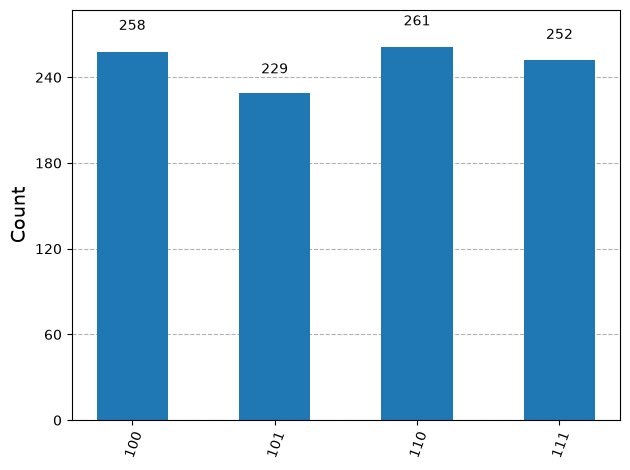

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

circuit = QuantumCircuit(3, 3)

# Prepare the qubit to be teleported
circuit.x(0)
circuit.barrier()

# Create an entangled Bell pair between qubits 1 and 2
circuit.h(1)
circuit.cx(1, 2)
circuit.barrier()

# Perform quantum teleportation operations
circuit.cx(0, 1)
circuit.h(0)
circuit.barrier()

# Measure qubits 0 and 1
circuit.measure([0, 1], [0, 1])
circuit.barrier()

# Apply corrections to qubit 2 based on the measurement results
circuit.cx(1, 2)
circuit.cz(0, 2)

# Measure the teleported qubit
circuit.measure(2, 2)

print(circuit.draw())

simulator = AerSimulator()
job = simulator.run(circuit, shots=1000)
counts = job.result().get_counts()
print("Measurement results:", counts)

plot_histogram(counts)